In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from scipy.sparse import hstack



In [3]:
df = pd.read_csv(r"train.csv")

In [4]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [5]:
df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [6]:
# Let's create another column "bad_comment" denoting any type of toxicity in the comment

df["bad_comment"] = df.iloc[:,2:].sum(axis = 1)
df["bad_comment"][df["bad_comment"] != 0] = 1
df.head(20)

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,1
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,0


In [7]:
train=df.sample(frac=0.7,random_state=42) #random state is a seed value
test=df.drop(train.index)
train_corpus = train['comment_text']
test_corpus = test['comment_text']

In [8]:
class_names = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate','bad_comment']

all_corpus = pd.concat([train_corpus, test_corpus])

In [9]:
# Word TF-IDF Vectorizer
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    stop_words='english',
    ngram_range=(1, 1),
    max_features=10000)
word_vectorizer.fit(all_corpus)
train_word_features = word_vectorizer.transform(train_corpus)
test_word_features = word_vectorizer.transform(test_corpus)

In [10]:
# Char TF-IDF Vectorizer
char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    stop_words='english',
    ngram_range=(2, 6),
    max_features=50000)
char_vectorizer.fit(all_corpus)
train_char_features = char_vectorizer.transform(train_corpus)
test_char_features = char_vectorizer.transform(test_corpus)

In [11]:
train_features = hstack([train_char_features, train_word_features])
test_features = hstack([test_char_features, test_word_features])

In [12]:
scores = []
submission = pd.DataFrame.from_dict({'id': test['id']})
submission_2 = pd.DataFrame.from_dict({'id': test['id']})
for class_name in class_names:
    train_target = train[class_name]
    classifier = LogisticRegression(C=0.1, solver='sag')

    cv_score = np.mean(cross_val_score(classifier, train_features, train_target, cv=5, scoring='roc_auc'))
    scores.append(cv_score)
    print('CV score for class {} is {}'.format(class_name, cv_score))

    classifier.fit(train_features, train_target)
    submission[class_name] = classifier.predict_proba(test_features)[:, 1]
    submission_2[class_name] = classifier.predict(test_features)

print('Total CV score is {}'.format(np.mean(scores)))

submission.to_csv('submission.csv', index=False)

CV score for class toxic is 0.9684635196180181
CV score for class severe_toxic is 0.9877860893677568
CV score for class obscene is 0.9844446665728338
CV score for class threat is 0.9852435606172041
CV score for class insult is 0.9772502499049139
CV score for class identity_hate is 0.9726949585084299
CV score for class bad_comment is 0.9682442011874312
Total CV score is 0.9777324636823697


In [13]:
submission.head(10)

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
2,000113f07ec002fd,0.037209,0.002693,0.015813,0.001655,0.013747,0.003064,0.042095
5,00025465d4725e87,0.016971,0.003696,0.012002,0.002296,0.010456,0.004670,0.018816
9,00040093b2687caa,0.045074,0.005252,0.020829,0.002475,0.021873,0.007067,0.046040
10,0005300084f90edc,0.001564,0.001236,0.002450,0.001110,0.002102,0.001425,0.001784
11,00054a5e18b50dd4,0.087249,0.006576,0.031040,0.003038,0.031590,0.008039,0.087876
13,0006f16e4e9f292e,0.042507,0.002771,0.012933,0.002209,0.014611,0.003794,0.049092
15,00078f8ce7eb276d,0.086146,0.005006,0.028527,0.003032,0.030453,0.007703,0.092613
16,0007e25b2121310b,0.176734,0.007341,0.050555,0.003385,0.054209,0.008374,0.184466
18,0009801bd85e5806,0.022389,0.004218,0.011312,0.002060,0.012385,0.004429,0.023382
19,0009eaea3325de8c,0.064497,0.003941,0.025958,0.002586,0.030377,0.005879,0.075183


In [16]:
submission_2.sum()

id               000113f07ec002fd00025465d4725e8700040093b2687c...
toxic                                                         2337
severe_toxic                                                   127
obscene                                                       1385
threat                                                           0
insult                                                        1161
identity_hate                                                   33
bad_comment                                                   2482
dtype: object



 toxic comment classification metrics


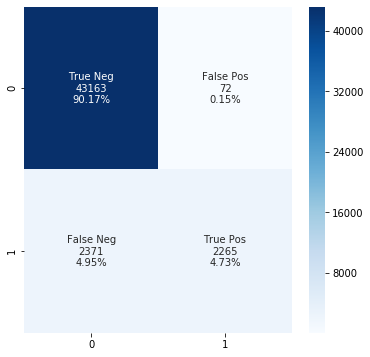



Accuracy=0.949
Precision=0.969
Recall=0.489
F1 Score=0.650


 severe_toxic comment classification metrics


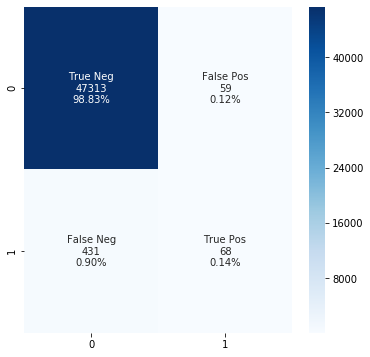



Accuracy=0.990
Precision=0.535
Recall=0.136
F1 Score=0.217


 obscene comment classification metrics


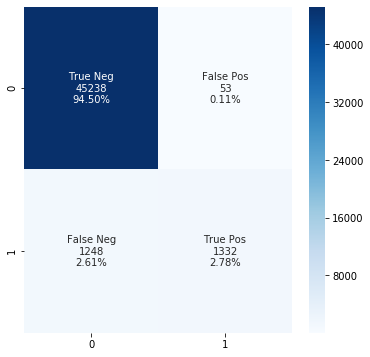



Accuracy=0.973
Precision=0.962
Recall=0.516
F1 Score=0.672


 threat comment classification metrics


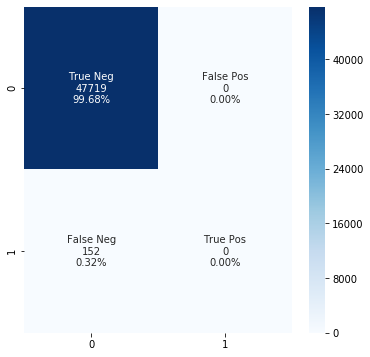

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\ipykernel_launcher.py:26: RuntimeWarning: invalid value encountered in longlong_scalars




Accuracy=0.997
Precision=nan
Recall=0.000
F1 Score=nan


 insult comment classification metrics


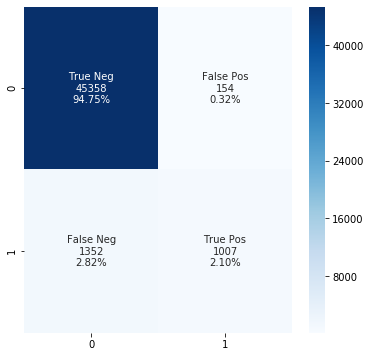



Accuracy=0.969
Precision=0.867
Recall=0.427
F1 Score=0.572


 identity_hate comment classification metrics


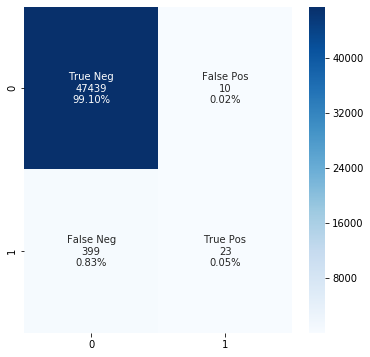



Accuracy=0.991
Precision=0.697
Recall=0.055
F1 Score=0.101


 bad_comment comment classification metrics


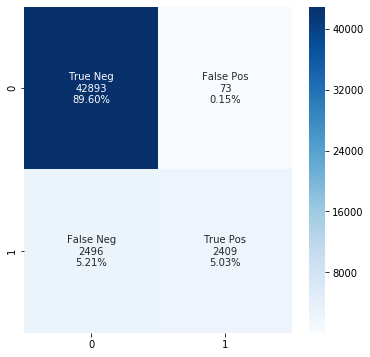



Accuracy=0.946
Precision=0.971
Recall=0.491
F1 Score=0.652


In [15]:
# Plotting Confusion Matrix

for class_name in class_names:
    
    print(f'\n\n {class_name} comment classification metrics')
    
    cf_matrix = confusion_matrix(test[class_name],submission_2[class_name])

    group_names = ['True Neg','False Pos','False Neg','True Pos']

    group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

    group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

    labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

    labels = np.asarray(labels).reshape(2,2)

    plt.figure(figsize=(6,6))
    ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
    bottom, top = ax.get_ylim()
    ax.set_ylim(bottom+0.5,top-0.5)
    plt.show()

    accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
    precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
    recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
    f1_score  = 2*precision*recall / (precision + recall)
    stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
    accuracy,precision,recall,f1_score)
    print(stats_text)